# Tesla Stock Price Prediction: Can a Model Beat "Same as Yesterday"?

## Goal
Predict Tesla's next-day closing price from its recent price history, and test honestly whether the model beats a simple "no change" guess.

## Data
- 1,258 trading days of TSLA prices, 16 Aug 2016 to 13 Aug 2021 (Open, High, Low, Close, Adj Close, Volume). Only the closing price is used.
- No missing values
- The price rose from about $45 to about $717 and peaked at $883, with most of the rise from 2020 onward
- Daily moves got bigger over time: the average absolute daily change was 2.15% in the training period and 3.43% in the test period

## First attempt and why it failed
The first version predicted the price itself from the previous 50 prices (scaled to 0–1) using XGBoost. It was off by about **$356** a day on average. Its predictions were almost a flat line between $158 and $166, because the training data never went above $177 and tree-based models like XGBoost cannot predict beyond the range they have seen. The test period (2020–21) was far above that range.

## Method (second attempt)
1. Predict the **daily % change** instead of the price, because % changes look similar in 2017 and in 2021.
2. Inputs: the previous 5 days' % changes.
3. Split by date, not at random: train on 24 Aug 2016 to 18 Feb 2020 (876 days) and test on 19 Feb 2020 to 13 Aug 2021 (376 days).
4. Model: XGBoost regressor (200 trees, depth 3, learning rate 0.05).
5. Compare against simple baselines: "no change" and "same as yesterday".

## Results (test period, 376 days)
| Measure | Model | Baseline |
|---|---|---|
| Average error, in % points | 3.558 | 3.427 ("no change") |
| Days with the direction (up/down) right | 50.8% | 53.5% ("always up") |
| Average error, in dollars | $14.77 | $14.15 ("same as yesterday") |

## Conclusions
- The model does **not** beat the simple baselines. It is slightly worse than "no change", and its direction accuracy is close to a coin flip.
- Switching from price to % change fixed the first attempt: the error on the same one-day-ahead question fell from about $356 to $14.77.
- The actual-vs-predicted price chart looks almost perfect, but only because each prediction starts from yesterday's real price. The baseline comparison is what shows the model adds nothing.
- This is typical for daily stock prices: past moves carry very little information about tomorrow's.

## Limitations and next steps
- Only past price changes were used. News, trading volume and market indices were not tested.
- The test period (2020–21) was unusually volatile, so results could differ in calmer years.
- One stock and one split. Testing over several periods would be more reliable.
- This is a learning project, not investment advice.

## 1. Setup and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

In [2]:
df = pd.read_csv('TSLA.csv')

In [3]:
df = df.rename(columns={'Date': 'date','Open':'open','High':'high','Low':'low','Close':'close',
                                'Adj Close':'adj_close','Volume':'volume'})
df.head()

,date,open,high,low,close,adj_close,volume
0,8/16/2016,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,8/17/2016,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,8/18/2016,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,8/19/2016,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,8/22/2016,44.834000,45.021999,44.535999,44.585999,44.585999,10327500


In [4]:
df['date'] = pd.to_datetime(df.date)
df

,date,open,high,low,close,adj_close,volume
0,2016-08-16,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,2016-08-17,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,2016-08-18,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,2016-08-19,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,2016-08-22,44.834000,45.021999,44.535999,44.585999,44.585999,10327500
...,...,...,...,...,...,...,...
1253,2021-08-09,710.169983,719.030029,705.130005,713.760010,713.760010,14715300
1254,2021-08-10,713.989990,716.590027,701.880005,709.989990,709.989990,13432300
1255,2021-08-11,712.710022,715.179993,704.210022,707.820007,707.820007,9800600
1256,2021-08-12,706.340027,722.799988,699.400024,722.250000,722.250000,17459100


## 2. Explore the data

Tesla stayed between about $40 and $75 until the end of 2019, then rose to about $880 by early 2021.

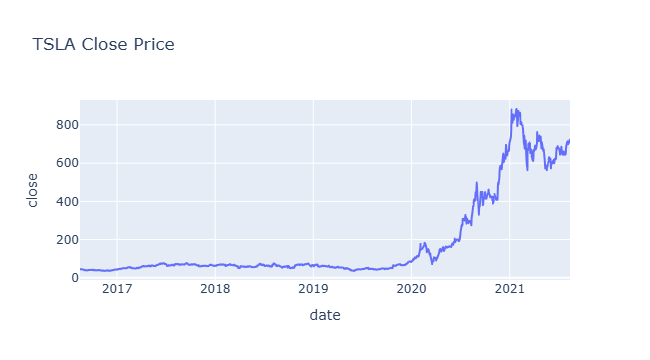

In [5]:
fig = px.line(df, x='date',y='close',title='TSLA Close Price')
fig.show()

### Daily % change


Price levels change a lot over time, but daily % changes look similar across the years, which makes them a better thing to predict. The swings get much larger from 2020.

        date      close    change
0 2016-08-16  44.722000       NaN
1 2016-08-17  44.647999 -0.165469
2 2016-08-18  44.702000  0.120948
3 2016-08-19  45.000000  0.666637
4 2016-08-22  44.585999 -0.920002


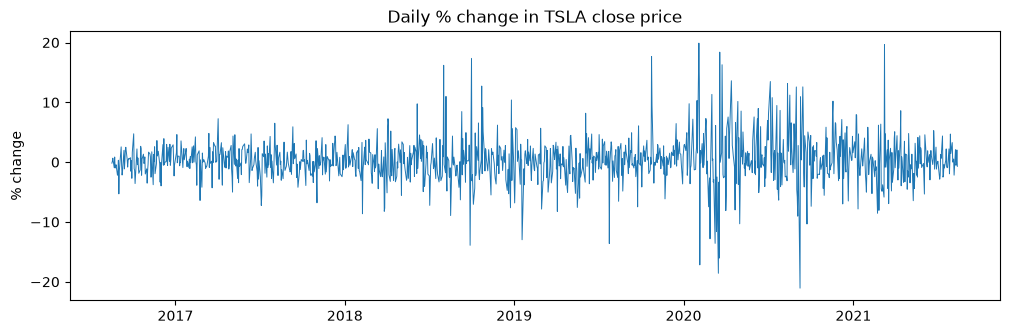

In [6]:
# How much did the price move each day, in percent?
df["change"] = df["close"].pct_change() * 100
print(df[["date", "close", "change"]].head())

plt.figure(figsize=(12, 3.5))
plt.plot(df["date"], df["change"], linewidth=0.7)
plt.title("Daily % change in TSLA close price")
plt.ylabel("% change")
plt.show()

## 3. Prepare the data

Each row's inputs are the previous 5 days' % changes, and the target is that day's % change.

In [7]:
n_lags = 5
for k in range(1, n_lags + 1):
    df[f"change_lag_{k}"] = df["change"].shift(k)   # the change k days ago

df["prev_close"] = df["close"].shift(1)             # yesterday's price (used later to turn % into $)

data = df.dropna().reset_index(drop=True)           # the first rows have no history, so drop them
feature_cols = [f"change_lag_{k}" for k in range(1, n_lags + 1)]

print(data.shape)
data[["date", "change"] + feature_cols].head(3)

(1252, 14)


,date,change,change_lag_1,change_lag_2,change_lag_3,change_lag_4,change_lag_5
0,2016-08-24,-0.987371,0.856771,-0.920002,0.666637,0.120948,-0.165469
1,2016-08-25,-0.745659,-0.987371,0.856771,-0.920002,0.666637,0.120948
2,2016-08-26,-0.438993,-0.745659,-0.987371,0.856771,-0.920002,0.666637


## 4. Split by date


Train on the past and test on the future, so there is no shuffling.

In [8]:
# Time series: train on the past, test on the future
cut = int(len(data) * 0.7)
train = data.iloc[:cut]
test = data.iloc[cut:]

X_train, y_train = train[feature_cols], train["change"]
X_test,  y_test  = test[feature_cols],  test["change"]

print("Train:", train["date"].iloc[0].date(), "to", train["date"].iloc[-1].date(), f"({len(train)} days)")
print("Test: ", test["date"].iloc[0].date(),  "to", test["date"].iloc[-1].date(),  f"({len(test)} days)")

Train: 2016-08-24 to 2020-02-18 (876 days)
Test:  2020-02-19 to 2021-08-13 (376 days)


## 5. Train the model

In [9]:
model = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)   # predicted % change for each test day

## 6. Evaluate against simple baselines


A model is only useful if it beats a simple guess.

In [10]:
actual = y_test.values

print("Average error, in percentage points:")
print("  Model:                    ", round(mean_absolute_error(actual, pred), 3))
print("  Baseline 'no change':     ", round(mean_absolute_error(actual, np.zeros(len(actual))), 3))
print()
print("Share of days where the direction (up/down) was right:")
print("  Model:                    ", round((np.sign(pred) == np.sign(actual)).mean(), 3))
print("  Baseline 'always up':     ", round((actual > 0).mean(), 3))

Average error, in percentage points:
  Model:                     3.558
  Baseline 'no change':      3.427

Share of days where the direction (up/down) was right:
  Model:                     0.508
  Baseline 'always up':      0.535


Average error in dollars:
  Model:                        $ 14.77
  Baseline 'same as yesterday': $ 14.15


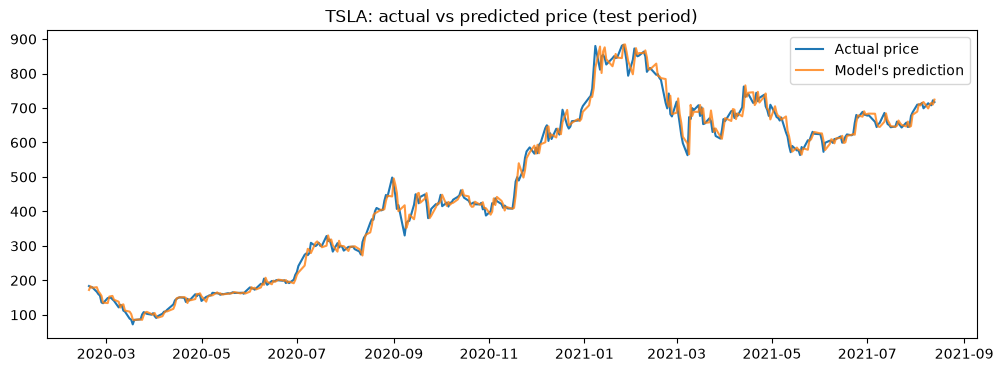

In [11]:
test = test.copy()
test["pred_price"] = test["prev_close"] * (1 + pred / 100)   # yesterday's price moved by the predicted %

print("Average error in dollars:")
print("  Model:                        $", round(mean_absolute_error(test["close"], test["pred_price"]), 2))
print("  Baseline 'same as yesterday': $", round(mean_absolute_error(test["close"], test["prev_close"]), 2))

plt.figure(figsize=(12, 4))
plt.plot(test["date"], test["close"], label="Actual price")
plt.plot(test["date"], test["pred_price"], label="Model's prediction", alpha=0.8)
plt.title("TSLA: actual vs predicted price (test period)")
plt.legend()
plt.show()

The chart looks almost perfect because each prediction starts from yesterday's real price. Compare the dollar errors, not the chart.

## 7. Conclusion

The model did not beat the simple baselines, so past daily price changes did not help predict tomorrow's move. The comparison against baselines is the main finding of this project.